In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import matplotlib.ticker as mticker
import math
import itertools
from typing import Literal
from matplotlib.ticker import FuncFormatter
from matplotlib.axes import Axes
from matplotlib.figure import Figure
import seaborn.objects as so
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [2]:
from sklearn import set_config
set_config(transform_output='pandas', display='diagram')

# Notebook Purpose

Notebook này được dùng để ứng dụng SHAP lên model tốt nhất (sau khi đã thông qua đánh giá toàn diện). Mục tiêu của Notebook là in ra những biến ảnh hưởng lớn nhất đến dự đoán của model, cùng với một số plot liên quan

In [3]:
application_train = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/application_train_sample.csv')
bureau = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/bureau_sample.csv')
bureau_balance = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/bureau_balance_sample.csv')
credit_card_balance = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/credit_card_balance_sample.csv')
installments_payments = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/instalments_payments_sample.csv')
previous_application = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/previous_application_sample.csv')
POS_CASH_balance = pd.read_csv('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/data/raw/POS_CASH_balance_sample.csv')

In [4]:
from sklearn.model_selection import train_test_split

X = application_train.drop(columns=['TARGET'])
y = application_train['TARGET']

# chia tập dữ liệu cho application_train
X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_train, y_train, stratify=y_train, test_size=0.2, random_state=42)

application_train_train = pd.concat([X_train, y_train], axis=1)
application_train_val = pd.concat([X_val, y_val], axis=1)
application_train_test = pd.concat([X_test, y_test], axis=1)

SK_ID_CURR_train = X_train['SK_ID_CURR'].values
SK_ID_CURR_val = X_val['SK_ID_CURR'].values
SK_ID_CURR_test = X_test['SK_ID_CURR'].values

# chia tập dữ liệu cho bureau
bureau_train = bureau[bureau['SK_ID_CURR'].isin(SK_ID_CURR_train)]
bureau_val = bureau[bureau['SK_ID_CURR'].isin(SK_ID_CURR_val)]
bureau_test = bureau[bureau['SK_ID_CURR'].isin(SK_ID_CURR_test)]

SK_ID_BUREAU_train = bureau_train['SK_ID_BUREAU'].values
SK_ID_BUREAU_val = bureau_val['SK_ID_BUREAU'].values
SK_ID_BUREAU_test = bureau_test['SK_ID_BUREAU'].values

# chia tập dữ liệu cho previous_application
previous_application_train = previous_application[previous_application['SK_ID_CURR'].isin(SK_ID_CURR_train)]
previous_application_val = previous_application[previous_application['SK_ID_CURR'].isin(SK_ID_CURR_val)]
previous_application_test = previous_application[previous_application['SK_ID_CURR'].isin(SK_ID_CURR_test)]

SK_ID_PREV_train = previous_application_train['SK_ID_PREV'].values
SK_ID_PREV_val = previous_application_val['SK_ID_PREV'].values
SK_ID_PREV_test = previous_application_test['SK_ID_PREV'].values

# chia tập dữ liệu cho bureau_balance
bureau_balance_train = bureau_balance[bureau_balance['SK_ID_BUREAU'].isin(SK_ID_BUREAU_train)]
bureau_balance_val = bureau_balance[bureau_balance['SK_ID_BUREAU'].isin(SK_ID_BUREAU_val)]
bureau_balance_test = bureau_balance[bureau_balance['SK_ID_BUREAU'].isin(SK_ID_BUREAU_test)]

# chia tập dữ liệu cho POS_CASH_balance
filter_pos_cash_train = (POS_CASH_balance['SK_ID_CURR'].isin(SK_ID_CURR_train)) & (POS_CASH_balance['SK_ID_PREV'].isin(SK_ID_PREV_train))
filter_pos_cash_val = (POS_CASH_balance['SK_ID_CURR'].isin(SK_ID_CURR_val)) & (POS_CASH_balance['SK_ID_PREV'].isin(SK_ID_PREV_val))
filter_pos_cash_test = (POS_CASH_balance['SK_ID_CURR'].isin(SK_ID_CURR_test)) & (POS_CASH_balance['SK_ID_PREV'].isin(SK_ID_PREV_test))

POS_CASH_balance_train = POS_CASH_balance[filter_pos_cash_train]
POS_CASH_balance_val = POS_CASH_balance[filter_pos_cash_val]
POS_CASH_balance_test = POS_CASH_balance[filter_pos_cash_test]

# chia tập dữ liệu cho instalments_payments
filter_instalments_train = (installments_payments['SK_ID_CURR'].isin(SK_ID_CURR_train)) & (installments_payments['SK_ID_PREV'].isin(SK_ID_PREV_train))
filter_instalments_val = (installments_payments['SK_ID_CURR'].isin(SK_ID_CURR_val)) & (installments_payments['SK_ID_PREV'].isin(SK_ID_PREV_val))
filter_instalments_test = (installments_payments['SK_ID_CURR'].isin(SK_ID_CURR_test)) & (installments_payments['SK_ID_PREV'].isin(SK_ID_PREV_test))

installments_payments_train = installments_payments[filter_instalments_train]
installments_payments_val = installments_payments[filter_instalments_val]
installments_payments_test = installments_payments[filter_instalments_test]

# chia tập dữ liệu cho credit_card_balance
filter_credit_train = (credit_card_balance['SK_ID_CURR'].isin(SK_ID_CURR_train)) & (credit_card_balance['SK_ID_PREV'].isin(SK_ID_PREV_train))
filter_credit_val = (credit_card_balance['SK_ID_CURR'].isin(SK_ID_CURR_val)) & (credit_card_balance['SK_ID_PREV'].isin(SK_ID_PREV_val))
filter_credit_test = (credit_card_balance['SK_ID_CURR'].isin(SK_ID_CURR_test)) & (credit_card_balance['SK_ID_PREV'].isin(SK_ID_PREV_test))

credit_card_balance_train = credit_card_balance[filter_credit_train]
credit_card_balance_val = credit_card_balance[filter_credit_val]
credit_card_balance_test = credit_card_balance[filter_credit_test]

In [5]:
previous_application_train['CHANNEL_TYPE'].value_counts()

CHANNEL_TYPE
Credit and cash offices       77793
Country-wide                  54120
Stone                         23685
Regional / Local              12022
Contact center                 7472
AP+ (Cash loan)                6339
Channel of corporate sales      734
Car dealer                       36
Name: count, dtype: int64

# Định nghĩa Pipeline

In [6]:
class AddPrefix(BaseEstimator, TransformerMixin):
    def __init__(self, prefix:str, exclude:list[str]):
        """
        Used to add prefix to columns' name
        
        Args:
            prefix: prefix added to columns' name
            exclude: columns that don't need prefix
        """
        self.prefix = prefix
        self.exclude = exclude

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        self.new_cols_name_ = [
            col if col in self.exclude else f'{self.prefix}_{col}'
            for col in X_copy.columns
        ]
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_copy.columns = self.new_cols_name_
        return X_copy

    def get_feature_names_out(self, input_features=None): # must have this method
        # must have 'input_features' parameter
        return self.new_cols_name_

In [7]:
class RemoveFeature(BaseEstimator, TransformerMixin):
    def __init__(self, columns_removed:list[str]):
        """
        columns_removed: columns which will be removed from dataset
        """
        self.columns_removed = columns_removed

    def fit(self, X:pd.DataFrame, y=None):
        missing = set(self.columns_removed) - set(X.columns) # check if columns's name removed is misspelled
        if missing:
            raise ValueError(f"Các cột sau không tồn tại trong dữ liệu: {missing}")
        
        # Giữ nguyên thứ tự cột gốc, chỉ loại bỏ cột cần xóa
        self.columns_selected_ = [
            col for col in X.columns if col not in self.columns_removed
        ]
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_new = X_copy[self.columns_selected_]
        return X_new

    def get_feature_names_out(self, input_features=None): # must have this method
        # must have 'input_features' parameter
        return self.columns_selected_

In [8]:
class Aggeration(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols:list[str], num_cols:list[str], groupby_col:str):
        """
        Used to perform aggregation by specific columns, num_cols and cat_cols will have differenct aggregation
        
        Args:
            cat_cols: categorical column's name
            num_cols: numerical column's name
            groupby_col: specific column's name used for groupby to perform aggregation
        """
        if groupby_col in num_cols:
            num_cols.remove(groupby_col)

        self.cat_cols = cat_cols
        self.num_cols = num_cols
        self.groupby_col = groupby_col

    def _build_agg_dict(self):
        agg_dict = {}
        for col in self.cat_cols:
            agg_dict[col] = ['mean'] # ['sum', 'mean']
        for col in self.num_cols:
            agg_dict[col] = ['mean', 'max'] # ['min', 'max', 'mean']
        return agg_dict
    
    def fit(self, X:pd.DataFrame, y=None):
        agg_dict = self._build_agg_dict()
        self.new_cols_name_ = [self.groupby_col] + [
            f'{col}_{stat.lower()}' for col, stats in agg_dict.items() for stat in stats
        ]
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        agg_dict = self._build_agg_dict()

        X_agg = X_copy.groupby(self.groupby_col).agg(agg_dict)
        X_agg.columns = self.new_cols_name_[1:]
        X_agg.reset_index(inplace=True)
        
        return X_agg

    def get_feature_names_out(self, input_features=None): # must have this method
        # must have 'input_features' parameter
        return self.new_cols_name_

In [9]:
class FrequencyGrouping(BaseEstimator, TransformerMixin):
    def __init__(self, threshold = 0.999999):
        self.threshold = threshold
    
    def fit(self, X: pd.DataFrame, y=None):
        X_copy = X.copy()
        self.dict_categories_ = {}
        columns = X_copy.columns

        for col in columns:
            col: str
            frequency = X_copy[col].value_counts(normalize=True)
            cum_frequency = np.cumsum(frequency)

            kept_categories = frequency[cum_frequency <= self.threshold].index.tolist()
            self.dict_categories_[col] = kept_categories

        return self
    
    def transform(self, X: pd.DataFrame):
        X_copy = X.copy()
        
        for col, kept_categories in self.dict_categories_.items():
            col: str
            kept_categories: list
            X_copy[col] = X_copy[col].apply(lambda x: x if x in kept_categories else 'Others')

        return X_copy

In [10]:
from sklearn.preprocessing import OrdinalEncoder
class ApplicationTrainPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()

        # auto detect features with missing ratio > 0.1, to remove them
        missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
        missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
        columns_remove_application_train = list(missing_ratio[missing_ratio['missing_ratio'] > 0.5].index)
        
        self.missing_ratio_feature_removed_application_train_ = RemoveFeature(columns_removed = columns_remove_application_train)
        X_copy = self.missing_ratio_feature_removed_application_train_.fit_transform(X_copy)

        # encode for categorical features
        obj_columns = list(X_copy.select_dtypes(include=['object', 'string']).columns)
        self.categorical_encoder_ = ColumnTransformer(
            transformers=[
                ('ordinal_encoding', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan), obj_columns)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
            # force_int_remainder_cols=False
        )
        X_copy = self.categorical_encoder_.fit_transform(X_copy)

        # auto detect binary features having ratio < 0.1 or ratio > 1 - 0.1, to remove them
        all_cols = list(X_copy.columns)
        binary_columns = [col for col in all_cols if set(X_copy[col].dropna().unique()).issubset({0, 1})]
        binary_columns_mean = X_copy[binary_columns].mean()
        binary_columns_remove = list(
            binary_columns_mean[(binary_columns_mean < 0.02) |
                         (binary_columns_mean > 1 - 0.02)].index
        )
        # binary_columns_remove.remove('TARGET')

        self.binary_feature_removed_application_train_ = RemoveFeature(columns_removed = binary_columns_remove)
        X_copy = self.binary_feature_removed_application_train_.fit_transform(X_copy)

        self.application_train_add_prefix_ = AddPrefix(prefix='AT', exclude=['SK_ID_CURR'])
        X_copy = self.application_train_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_final = self.missing_ratio_feature_removed_application_train_.transform(X_copy)
        X_final = self.categorical_encoder_.transform(X_final)
        X_final = self.binary_feature_removed_application_train_.transform(X_final)
        X_final = self.application_train_add_prefix_.transform(X_final)
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.application_train_add_prefix_.get_feature_names_out()

In [11]:
class BureauBalancePipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        cat_cols = list(X_copy.select_dtypes(include=['object', 'string']).columns)
        num_cols = list(X_copy.select_dtypes(include=['number']).columns)

        cat_pipeline = Pipeline([
            ('frequency_grouping', FrequencyGrouping()),
            ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
        ])
        
        self.cat_cols_transformer_ = ColumnTransformer(
            transformers=[
                ('cat_processing', cat_pipeline, cat_cols)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
            # force_int_remainder_cols=False
        )
        X_copy = self.cat_cols_transformer_.fit_transform(X_copy)

        cat_cols_after_onehot = [col for col in X_copy.columns if col.startswith(tuple([f"{column}_" for column in cat_cols]))]
        self.aggregate_ = Aggeration(cat_cols=cat_cols_after_onehot, num_cols=num_cols, groupby_col='SK_ID_BUREAU')
        X_copy = self.aggregate_.fit_transform(X_copy)

        self.bureau_balance_add_prefix_ = AddPrefix(prefix='BB', exclude=['SK_ID_BUREAU'])
        X_copy = self.bureau_balance_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_final = self.cat_cols_transformer_.transform(X_copy)
        X_final = self.aggregate_.transform(X_final)
        X_final = self.bureau_balance_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.bureau_balance_add_prefix_.get_feature_names_out()

In [12]:
class POSCASHPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        cat_cols = list(X_copy.select_dtypes(include=['object', 'string']).columns)
        num_cols = list(X_copy.select_dtypes(include=['number']).columns)
        
        cat_pipeline = Pipeline([
            ('frequency_grouping', FrequencyGrouping()),
            ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
        ])
        
        self.cat_cols_transformer_ = ColumnTransformer(
            transformers=[
                ('cat_processing', cat_pipeline, cat_cols)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
            # force_int_remainder_cols=False
        )
        X_copy = self.cat_cols_transformer_.fit_transform(X_copy)

        cat_cols_after_onehot = [col for col in X_copy.columns if col.startswith(tuple([f"{column}_" for column in cat_cols]))]
        self.aggregate_ = Aggeration(cat_cols=cat_cols_after_onehot, num_cols=num_cols, groupby_col='SK_ID_PREV')
        X_copy = self.aggregate_.fit_transform(X_copy)
        
        self.pos_cash_add_prefix_ = AddPrefix(prefix='PC', exclude=['SK_ID_PREV'])
        X_copy = self.pos_cash_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        
        X_final = self.cat_cols_transformer_.transform(X_copy)
        X_final = self.aggregate_.transform(X_final)
        X_final = self.pos_cash_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.pos_cash_add_prefix_.get_feature_names_out()

In [13]:
class InstallmentPaymentPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        cat_cols = list(X_copy.select_dtypes(include=['object', 'string']).columns) # empty list
        num_cols = list(X_copy.select_dtypes(include=['number']).columns)
        
        self.aggregate_ = Aggeration(cat_cols=cat_cols, num_cols=num_cols, groupby_col='SK_ID_PREV')
        X_copy = self.aggregate_.fit_transform(X_copy)

        self.installment_payment_add_prefix_ = AddPrefix(prefix='IP', exclude=['SK_ID_PREV'])
        X_copy = self.installment_payment_add_prefix_.fit_transform(X_copy)

        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        
        X_final = self.aggregate_.transform(X_copy)
        X_final = self.installment_payment_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.installment_payment_add_prefix_.get_feature_names_out()

In [14]:
class CreditCardPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)

        # auto detect features with missing ratio > 0.1, to remove them
        missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
        missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
        columns_remove_credit_card = list(missing_ratio[missing_ratio['missing_ratio'] > 0.5].index)

        self.feature_removed_credit_card_ = RemoveFeature(columns_removed = columns_remove_credit_card)
        X_copy = self.feature_removed_credit_card_.fit_transform(X_copy)

        cat_cols = list(X_copy.select_dtypes(include=['object', 'string']).columns)
        num_cols = list(X_copy.select_dtypes(include=['number']).columns)

        cat_pipeline = Pipeline([
            ('frequency_grouping', FrequencyGrouping()),
            ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
        ])
        
        self.cat_cols_transformer_ = ColumnTransformer(
            transformers=[
                ('cat_processing', cat_pipeline, cat_cols)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False, # not containing the transformer name in columns of Dataframe
            # force_int_remainder_cols=False
        )
        X_copy = self.cat_cols_transformer_.fit_transform(X_copy)

        cat_cols_after_onehot = [col for col in X_copy.columns if col.startswith(tuple([f"{column}_" for column in cat_cols]))]
        self.aggregate_ = Aggeration(cat_cols=cat_cols_after_onehot, num_cols=num_cols, groupby_col='SK_ID_PREV')
        X_copy = self.aggregate_.fit_transform(X_copy)

        self.credit_card_add_prefix_ = AddPrefix(prefix='CC', exclude=['SK_ID_PREV'])
        X_copy = self.credit_card_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        X_copy.drop(columns=['SK_ID_CURR'], inplace=True)
        
        X_final = self.feature_removed_credit_card_.transform(X_copy)
        X_final = self.cat_cols_transformer_.transform(X_final)
        X_final = self.aggregate_.transform(X_final)
        X_final = self.credit_card_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.credit_card_add_prefix_.get_feature_names_out()

In [15]:
class BureauPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()

        # auto detect features with missing ratio > 0.1, to remove them
        missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
        missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
        columns_remove_bureau = list(missing_ratio[missing_ratio['missing_ratio'] > 0.5].index)

        self.feature_removed_bureau_ = RemoveFeature(columns_removed = columns_remove_bureau)
        X_copy = self.feature_removed_bureau_.fit_transform(X_copy)

        self.bureau_add_prefix_ = AddPrefix(prefix='B', exclude=['SK_ID_CURR', 'SK_ID_BUREAU'])
        X_copy = self.bureau_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        
        X_final = self.feature_removed_bureau_.transform(X_copy)
        X_final = self.bureau_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.bureau_add_prefix_.get_feature_names_out()

In [16]:
class PreviousApplicationPipeline(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X:pd.DataFrame, y=None):
        X_copy = X.copy()

        # auto detect features with missing ratio > 0.1, to remove them
        missing_ratio = X_copy.isnull().mean().astype(float).to_frame()
        missing_ratio = missing_ratio.rename(columns={0: "missing_ratio"})
        columns_remove_previous_application = list(missing_ratio[missing_ratio['missing_ratio'] > 0.5].index)
        
        self.feature_removed_previous_application_ = RemoveFeature(columns_removed = columns_remove_previous_application)
        X_copy = self.feature_removed_previous_application_.fit_transform(X_copy)

        self.previous_application_add_prefix_ = AddPrefix(prefix='PA', exclude=['SK_ID_CURR', 'SK_ID_PREV'])
        X_copy = self.previous_application_add_prefix_.fit_transform(X_copy)
        
        return self

    def transform(self, X:pd.DataFrame):
        X_copy = X.copy()
        
        X_final = self.feature_removed_previous_application_.transform(X_copy)
        X_final = self.previous_application_add_prefix_.transform(X_final)
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.previous_application_add_prefix_.get_feature_names_out()

In [17]:
class MergePipeline:
    def __init__(self):
        self.bureau_balance_pipeline = BureauBalancePipeline()
        self.installment_payment_pipeline = InstallmentPaymentPipeline()
        self.pos_cash_pipeline = POSCASHPipeline()
        self.credit_card_pipeline = CreditCardPipeline()
        self.previous_application_pipeline = PreviousApplicationPipeline()
        self.bureau_pipeline = BureauPipeline()
        self.application_pipeline = ApplicationTrainPipeline()

        # Lưu các transformer/aggregator theo tên nhóm, thay vì tạo nhiều thuộc tính rời rạc
        self.group_transformers_ = {}

    def _encode_and_aggregate_fit(self, df: pd.DataFrame, group_name: str, groupby_col: str = 'SK_ID_CURR'):
        """
        Dùng khi fit: one-hot encode + aggregate cho 1 nhóm bảng (bureau hoặc previous_application),
        đồng thời lưu lại các transformer đã fit để dùng lại lúc transform.
        """
        cat_cols = list(df.select_dtypes(include=['object', 'string']).columns)
        num_cols = list(df.select_dtypes(include=['number']).columns)

        cat_pipeline = Pipeline([
            ('frequency_grouping', FrequencyGrouping()),
            ('one_hot_encode', OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')),
        ])
        
        cat_transformer = ColumnTransformer(
            transformers=[
                ('cat_processing', cat_pipeline, cat_cols)
            ],
            remainder='passthrough',
            verbose_feature_names_out=False,
        )
        df_encoded = cat_transformer.fit_transform(df)

        cat_cols_after_onehot = [
            col for col in df_encoded.columns
            if col.startswith(tuple(f"{c}_" for c in cat_cols))
        ]

        aggregator = Aggeration(cat_cols=cat_cols_after_onehot, num_cols=num_cols, groupby_col=groupby_col)
        df_agg = aggregator.fit_transform(df_encoded)

        # Lưu lại để transform() dùng sau này
        self.group_transformers_[group_name] = {
            'cat_transformer': cat_transformer,
            'aggregator': aggregator,
        }

        return df_agg

    def _encode_and_aggregate_transform(self, df: pd.DataFrame, group_name: str):
        """Dùng khi transform: áp dụng lại transformer đã fit cho nhóm tương ứng."""
        transformers = self.group_transformers_[group_name]
        df_encoded = transformers['cat_transformer'].transform(df)
        df_agg = transformers['aggregator'].transform(df_encoded)
        return df_agg

    def fit(self, bureau_balance:pd.DataFrame, POS_CASH_balance:pd.DataFrame, application_train:pd.DataFrame,
             credit_card_balance:pd.DataFrame, previous_application:pd.DataFrame, bureau:pd.DataFrame, installments_payments:pd.DataFrame):

        bureau_balance_transform = self.bureau_balance_pipeline.fit_transform(bureau_balance)
        installments_payments_transform = self.installment_payment_pipeline.fit_transform(installments_payments)
        POS_CASH_balance_transform = self.pos_cash_pipeline.fit_transform(POS_CASH_balance)
        credit_card_balance_transform = self.credit_card_pipeline.fit_transform(credit_card_balance)
        previous_application_transform = self.previous_application_pipeline.fit_transform(previous_application)
        bureau_transform = self.bureau_pipeline.fit_transform(bureau)
        application_train_transform = self.application_pipeline.fit_transform(application_train)

        # --- Nhóm bureau ---
        merge_bureau = bureau_transform.merge(bureau_balance_transform, on='SK_ID_BUREAU', how='left')
        merge_bureau.drop(columns=['SK_ID_BUREAU'], inplace=True)
        merge_bureau = self._encode_and_aggregate_fit(merge_bureau, group_name='bureau')

        # --- Nhóm previous_application ---
        merge_prev = previous_application_transform.merge(credit_card_balance_transform, on='SK_ID_PREV', how='left')
        merge_prev = merge_prev.merge(POS_CASH_balance_transform, on='SK_ID_PREV', how='left')
        merge_prev = merge_prev.merge(installments_payments_transform, on='SK_ID_PREV', how='left')
        merge_prev.drop(columns=['SK_ID_PREV'], inplace=True)
        merge_prev = self._encode_and_aggregate_fit(merge_prev, group_name='previous_application')

        # --- Merge cuối cùng ---
        final_dataset = application_train_transform.merge(merge_prev, on='SK_ID_CURR', how='left')
        final_dataset = final_dataset.merge(merge_bureau, on='SK_ID_CURR', how='left')
        # self.final_dataset_ = final_dataset

        return self

    def transform(self, bureau_balance:pd.DataFrame, POS_CASH_balance:pd.DataFrame, application_train:pd.DataFrame,
                   credit_card_balance:pd.DataFrame, previous_application:pd.DataFrame, bureau:pd.DataFrame, installments_payments:pd.DataFrame):

        bureau_balance_transform = self.bureau_balance_pipeline.transform(bureau_balance)
        installments_payments_transform = self.installment_payment_pipeline.transform(installments_payments)
        POS_CASH_balance_transform = self.pos_cash_pipeline.transform(POS_CASH_balance)
        credit_card_balance_transform = self.credit_card_pipeline.transform(credit_card_balance)
        previous_application_transform = self.previous_application_pipeline.transform(previous_application)
        bureau_transform = self.bureau_pipeline.transform(bureau)
        application_train_transform = self.application_pipeline.transform(application_train)

        merge_bureau = bureau_transform.merge(bureau_balance_transform, on='SK_ID_BUREAU', how='left')
        merge_bureau.drop(columns=['SK_ID_BUREAU'], inplace=True)
        merge_bureau = self._encode_and_aggregate_transform(merge_bureau, group_name='bureau')

        merge_prev = previous_application_transform.merge(credit_card_balance_transform, on='SK_ID_PREV', how='left')
        merge_prev = merge_prev.merge(POS_CASH_balance_transform, on='SK_ID_PREV', how='left')
        merge_prev = merge_prev.merge(installments_payments_transform, on='SK_ID_PREV', how='left')
        merge_prev.drop(columns=['SK_ID_PREV'], inplace=True)
        merge_prev = self._encode_and_aggregate_transform(merge_prev, group_name='previous_application')

        final_dataset = application_train_transform.merge(merge_prev, on='SK_ID_CURR', how='left')
        final_dataset = final_dataset.merge(merge_bureau, on='SK_ID_CURR', how='left')

        return final_dataset

In [18]:
import re
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

class FeatureEngineeringPipeline(BaseEstimator, TransformerMixin):
    def __init__(self, missing_threshold: float = 0.1, imbalance_threshold: float = 0.02):
        self.missing_threshold = missing_threshold
        self.imbalance_threshold = imbalance_threshold

    def fit(self, X: pd.DataFrame, y=None):
        X_copy = X.copy()

        # Bước 1: loại cột có tỷ lệ missing quá cao
        missing_ratio = X_copy.isnull().mean()
        columns_to_remove = list(missing_ratio[missing_ratio > self.missing_threshold].index)
        self.feature_remove_ = RemoveFeature(columns_removed=columns_to_remove)
        # X_copy = self.feature_remove_.fit_transform(X_copy)

        # auto detect binary features having ratio < 0.1 or ratio > 1 - 0.1, to remove them
        all_cols = list(X_copy.columns)
        binary_columns = [col for col in all_cols if set(X_copy[col].dropna().unique()).issubset({0, 1})]
        binary_columns_mean = X_copy[binary_columns].mean()
        binary_columns_remove = list(
            binary_columns_mean[(binary_columns_mean < self.imbalance_threshold) |
                         (binary_columns_mean > 1 - self.imbalance_threshold)].index
        )

        self.binary_feature_remove_ = RemoveFeature(columns_removed=binary_columns_remove)
        # X_copy = self.binary_feature_remove_.fit_transform(X_copy)

        non_binary_columns = [col for col in all_cols if col not in binary_columns]
        self.robust_scaler_ = RobustScaler()
        X_copy = self.robust_scaler_.fit_transform(X_copy)
        
        self.imputer_ = SimpleImputer(strategy='constant', fill_value=0)
        X_copy = self.imputer_.fit_transform(X_copy)

        self.modified_columns_ = [re.sub(r'[^\w]+', '_', str(col)) for col in X_copy.columns]
        # X_copy.columns = self.modified_columns_

        return self

    def transform(self, X: pd.DataFrame):
        X_copy = X.copy()

        X_final = X_copy
        # X_final = self.feature_remove_.transform(X_final)
        # X_final = self.binary_feature_remove_.transform(X_final)
        X_final = self.robust_scaler_.transform(X_final)
        X_final = self.imputer_.transform(X_final)
        X_final.columns = self.modified_columns_
        
        return X_final

    def get_feature_names_out(self, input_features=None):
        return self.feature_remove_.get_feature_names_out()

# Load Pipeline

In [19]:
import joblib 

merge_pipeline = joblib.load('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/models/artifacts/merge_pipeline.joblib')
calibrated_lgb_with_weight_tuned_pipeline = joblib.load('/Users/thuyduc/Projects/AI/AI Sandbox/Services/CreditRiskAgent/models/saved_models/calibrated_lgb_with_weight_tuned_pipeline.joblib')
# lgb_with_weight_tuned_pipeline = joblib.load('/kaggle/input/models/thuyduc/model-pipeline-final/scikitlearn/default/1/lgb_tuned_pipeline.joblib')

In [20]:
final_dataset_test = merge_pipeline.transform(bureau_balance_test, POS_CASH_balance_test, application_train_test, credit_card_balance_test, \
                                              previous_application_test, bureau_test, installments_payments_test)

final_dataset_val = merge_pipeline.transform(bureau_balance_val, POS_CASH_balance_val, application_train_val, credit_card_balance_val, \
                                              previous_application_val, bureau_val, installments_payments_val)

/var/folders/8x/tgp52k0d76d0pmwhf9y3clp80000gn/T/ipykernel_43974/1809094098.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_agg.reset_index(inplace=True)
/var/folders/8x/tgp52k0d76d0pmwhf9y3clp80000gn/T/ipykernel_43974/1809094098.py:39: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_agg.reset_index(inplace=True)


In [21]:
X_test = final_dataset_test.drop(columns=['AT_TARGET', 'SK_ID_CURR'])
y_test = final_dataset_test['AT_TARGET']

X_val = final_dataset_val.drop(columns=['AT_TARGET', 'SK_ID_CURR'])
y_val = final_dataset_val['AT_TARGET']

# Global Interpretation from Tree Model

Trong phần này, ta sẽ lấy ra những feature có tầm ảnh hưởng lớn nhất đến dự đoán của mô hình cây, đây sẽ là những **global feature** mà mô hình cây cho là quan trọng nhất trong tất cả các mẫu để đưa ra dự đoán


In [22]:
# a feature has a low feature_importance -> the feature was not picked by the tree, 
# likely because another feature encodes the same information.

def plot_feature_importances(estimators_dict:dict, plots_each_row:int):
    num_plots = len(estimators_dict)
    number_rows = math.ceil(num_plots / plots_each_row)
        
    fig, axes = plt.subplots(nrows=number_rows, ncols=plots_each_row, figsize=(16, 8),) # sharey=True
    axes = np.array(axes).reshape(number_rows, plots_each_row)
    coordinates = list(itertools.product(range(number_rows), range(plots_each_row)))
    
    for coor, (estimator_name, estimator) in zip(coordinates, estimators_dict.items()):
        try:
            series = pd.Series(
                data = estimator.feature_importances_,
                index = estimator.feature_name_in_
            )
        except AttributeError:
            series = pd.Series(
                data = estimator.feature_importances_,
                index = estimator.feature_name_
            )
        series = series.sort_values(ascending=True)
        series = series.tail(25) # Show top 15 features
        n_features = series.shape[0]
        colors = plt.cm.tab20(np.linspace(0, 1, n_features))
        
        bars = axes[coor].barh(range(n_features), series.values, align='center', color=colors, edgecolor="black")
        axes[coor].set_yticks(np.arange(n_features), series.index, fontsize=10)
        
        axes[coor].set_xlabel("Feature importance", fontsize=12, weight='bold')
        axes[coor].set_ylabel("Feature", fontsize=12, weight='bold')
        axes[coor].set_title(estimator_name, fontsize=14, weight='bold')

        # Add gridlines for better contrast
        axes[coor].grid(axis='x', linestyle='--', alpha=0.6)
    
        # Add value labels on bars
        for bar in bars:
            axes[coor].text(bar.get_width() + 0.002, 
                     bar.get_y() + bar.get_height()/2, 
                     f"{bar.get_width():.3f}",
                     va='center', fontsize=9, color='black')

    # hide any unused axes
    for coor in coordinates[num_plots:]:
        fig.delaxes(axes[coor])

    return series

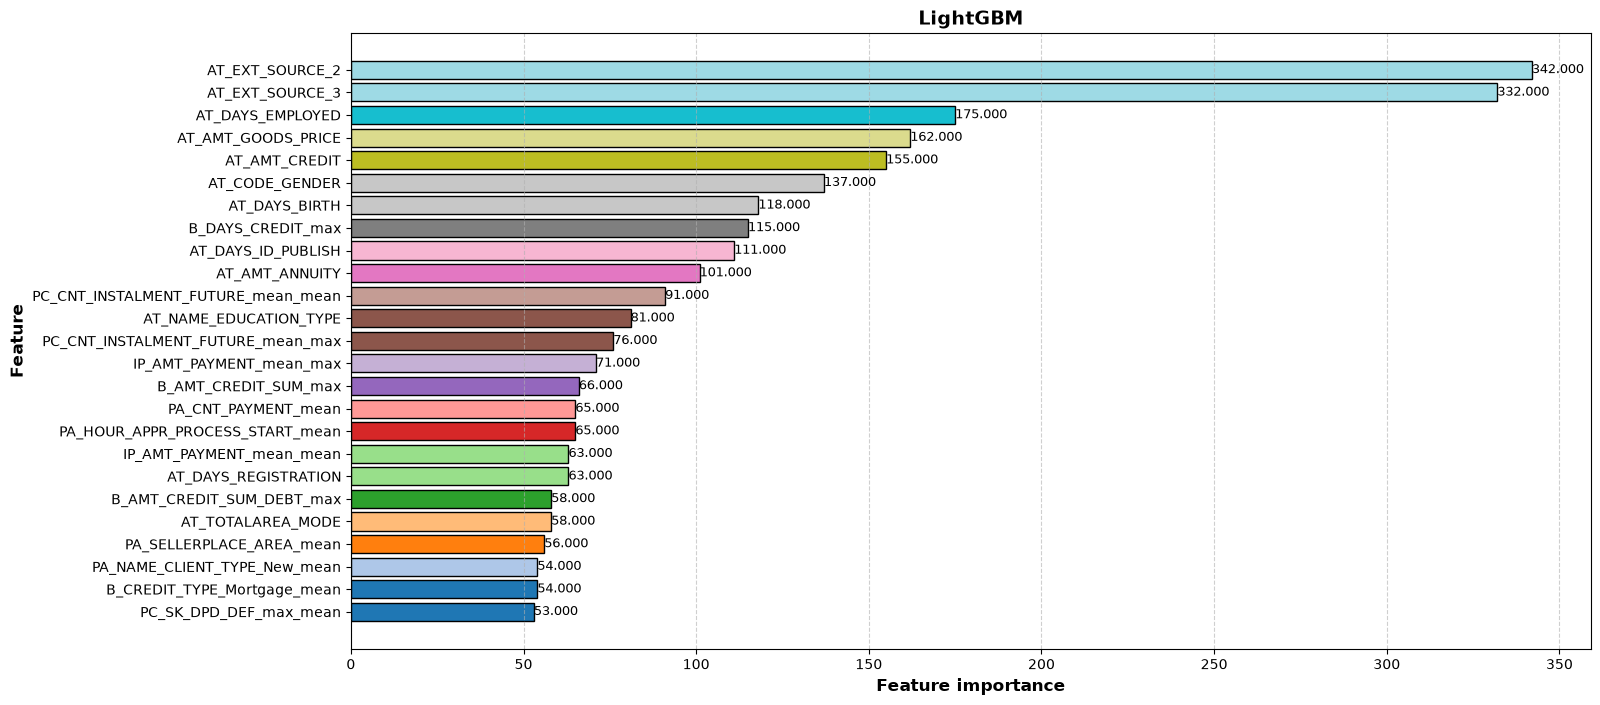

In [23]:
tuned_lgb = calibrated_lgb_with_weight_tuned_pipeline.estimator[-1]

estimators_dict={
    'LightGBM': tuned_lgb, # just model estimator
}
plots_each_row=1

series = plot_feature_importances(estimators_dict, plots_each_row)

In [63]:
series.sort_values(ascending=False).index

Index(['AT_EXT_SOURCE_2', 'AT_EXT_SOURCE_3', 'AT_DAYS_EMPLOYED',
       'AT_AMT_GOODS_PRICE', 'AT_AMT_CREDIT', 'AT_CODE_GENDER',
       'AT_DAYS_BIRTH', 'B_DAYS_CREDIT_max', 'AT_DAYS_ID_PUBLISH',
       'AT_AMT_ANNUITY', 'PC_CNT_INSTALMENT_FUTURE_mean_mean',
       'AT_NAME_EDUCATION_TYPE', 'PC_CNT_INSTALMENT_FUTURE_mean_max',
       'IP_AMT_PAYMENT_mean_max', 'B_AMT_CREDIT_SUM_max',
       'PA_CNT_PAYMENT_mean', 'PA_HOUR_APPR_PROCESS_START_mean',
       'IP_AMT_PAYMENT_mean_mean', 'AT_DAYS_REGISTRATION',
       'B_AMT_CREDIT_SUM_DEBT_max', 'AT_TOTALAREA_MODE',
       'PA_SELLERPLACE_AREA_mean', 'B_CREDIT_TYPE_Mortgage_mean',
       'PA_NAME_CLIENT_TYPE_New_mean', 'PC_SK_DPD_DEF_max_mean'],
      dtype='str')

# SHAP Plot for Local Interpretation

Trong phần này, ta sẽ thực hiện SHAP cho từng instance cụ thể, để thể hiện Local Interpretation, từ đó cho thấy SHAP có thể được dùng để giải thích kết quả dự đoán của mô hình cho từng instance (từng khách hàng)

In [24]:
background = X_val.sample(1000, random_state=42)

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV
import shap

class LocalInterpretation:
    def __init__(self, background_data:pd.DataFrame, estimator, optimal_threshold:float=0.5):
        self.optimal_threshold = optimal_threshold

        if isinstance(estimator, CalibratedClassifierCV):
            self.model = estimator
            
            def predict_proba_positive(X):
                if isinstance(X, np.ndarray):
                    X = pd.DataFrame(X, columns=background_data.columns)
                return self.model.predict_proba(X)[:, 1]

            summary_background_data = shap.utils.sample(background_data, 100, random_state=42)
            self.explainer = shap.KernelExplainer(predict_proba_positive, summary_background_data, link="identity")
            
        elif isinstance(estimator, Pipeline):
            self.model = estimator[-1]
            self.transformer = estimator[:-1]
            
            background_transformed = self.transformer.transform(background_data)
            self.explainer = shap.TreeExplainer(model=self.model, model_output="probability", feature_perturbation='interventional', data=background_transformed)
        
        else:
            raise TypeError("estimator phải là Pipeline hoặc CalibratedClassifierCV")
        
        self.baseline_value = self.explainer.expected_value
        
    def get_top_features_with_shap_values(self, X_raw:pd.DataFrame, top_features:int=10):
        # X_raw is DataFrame that only has one row
        np.random.seed(42)
        if isinstance(self.explainer, shap.KernelExplainer):
            shap_values = self.explainer.shap_values(X_raw, nsamples=500)
            prob_positive = self.model.predict_proba(X_raw)[:, 1][0]
            shap_df = pd.DataFrame({'feature': X_raw.columns, 'shap_value': shap_values[0], 'abs_shap': np.abs(shap_values[0])})

        elif isinstance(self.explainer, shap.TreeExplainer):
            X_transformed = self.transformer.transform(X_raw)
            shap_values = self.explainer.shap_values(X_transformed)
            prob_positive = self.model.predict_proba(X_transformed)[:, 1][0]
            shap_df = pd.DataFrame({'feature': X_transformed.columns, 'shap_value': shap_values[0], 'abs_shap': np.abs(shap_values[0])})

        
        late_payment = 'True' if prob_positive >= self.optimal_threshold else 'False'
        top = shap_df.sort_values('abs_shap', ascending=False).head(top_features).reset_index(drop=True)

        top_features = top['feature'].values
        top_shap_values = np.round(top['shap_value'].values, 4)
        top_features_dict = dict(zip(top_features, top_shap_values))
        
        result = {
            'baseline value': np.round(self.baseline_value, 4),
            'probability for positive class': np.round(prob_positive, 4),
            'late payment?': late_payment,
            'top feature attribution': top_features_dict
        }

        return result

/opt/anaconda3/envs/my_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [44]:
final_dataset_test[final_dataset_test['SK_ID_CURR'] == 427696]

,AT_NAME_CONTRACT_TYPE,AT_CODE_GENDER,AT_FLAG_OWN_CAR,AT_FLAG_OWN_REALTY,AT_NAME_TYPE_SUITE,AT_NAME_INCOME_TYPE,AT_NAME_EDUCATION_TYPE,AT_NAME_FAMILY_STATUS,AT_NAME_HOUSING_TYPE,AT_OCCUPATION_TYPE,...,BB_STATUS_C_mean_mean,BB_STATUS_C_mean_max,BB_STATUS_Others_mean_mean,BB_STATUS_Others_mean_max,BB_STATUS_X_mean_mean,BB_STATUS_X_mean_max,BB_MONTHS_BALANCE_mean_mean,BB_MONTHS_BALANCE_mean_max,BB_MONTHS_BALANCE_max_mean,BB_MONTHS_BALANCE_max_max
44,0.0,0.0,0.0,1.0,6.0,3.0,4.0,1.0,1.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [45]:
y_test[44:45]

44    1
Name: AT_TARGET, dtype: int64

In [46]:
X_test[44:45]

,AT_NAME_CONTRACT_TYPE,AT_CODE_GENDER,AT_FLAG_OWN_CAR,AT_FLAG_OWN_REALTY,AT_NAME_TYPE_SUITE,AT_NAME_INCOME_TYPE,AT_NAME_EDUCATION_TYPE,AT_NAME_FAMILY_STATUS,AT_NAME_HOUSING_TYPE,AT_OCCUPATION_TYPE,...,BB_STATUS_C_mean_mean,BB_STATUS_C_mean_max,BB_STATUS_Others_mean_mean,BB_STATUS_Others_mean_max,BB_STATUS_X_mean_mean,BB_STATUS_X_mean_max,BB_MONTHS_BALANCE_mean_mean,BB_MONTHS_BALANCE_mean_max,BB_MONTHS_BALANCE_max_mean,BB_MONTHS_BALANCE_max_max
44,0.0,0.0,0.0,1.0,6.0,3.0,4.0,1.0,1.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [27]:
optimal_threshold_calibrated = 0.08644900452917655
# optimal_threshold_base = 0.3441317362531742

local_interpreter = LocalInterpretation(background_data=background, estimator=calibrated_lgb_with_weight_tuned_pipeline, optimal_threshold=optimal_threshold_calibrated)
local_interpreter.get_top_features_with_shap_values(X_test[-1:], top_features=10)

100%|██████████| 1/1 [00:00<00:00,  1.61it/s]


{'baseline value': np.float64(0.0722),
 'probability for positive class': np.float64(0.2356),
 'late payment?': 'True',
 'top feature attribution': {'AT_EXT_SOURCE_2': np.float64(0.1086),
  'AT_EXT_SOURCE_3': np.float64(0.0303),
  'AT_CODE_GENDER': np.float64(0.0063),
  'PC_SK_DPD_max_mean': np.float64(0.0045),
  'PC_SK_DPD_mean_mean': np.float64(0.0042),
  'PA_NAME_CONTRACT_STATUS_Approved_mean': np.float64(0.003),
  'PA_CODE_REJECT_REASON_XAP_mean': np.float64(0.0023),
  'PC_MONTHS_BALANCE_mean_mean': np.float64(0.0018),
  'AT_DAYS_REGISTRATION': np.float64(0.0013),
  'IP_AMT_INSTALMENT_max_mean': np.float64(0.0011)}}

## Waterfall Plot

100%|██████████| 1/1 [00:00<00:00,  1.76it/s]


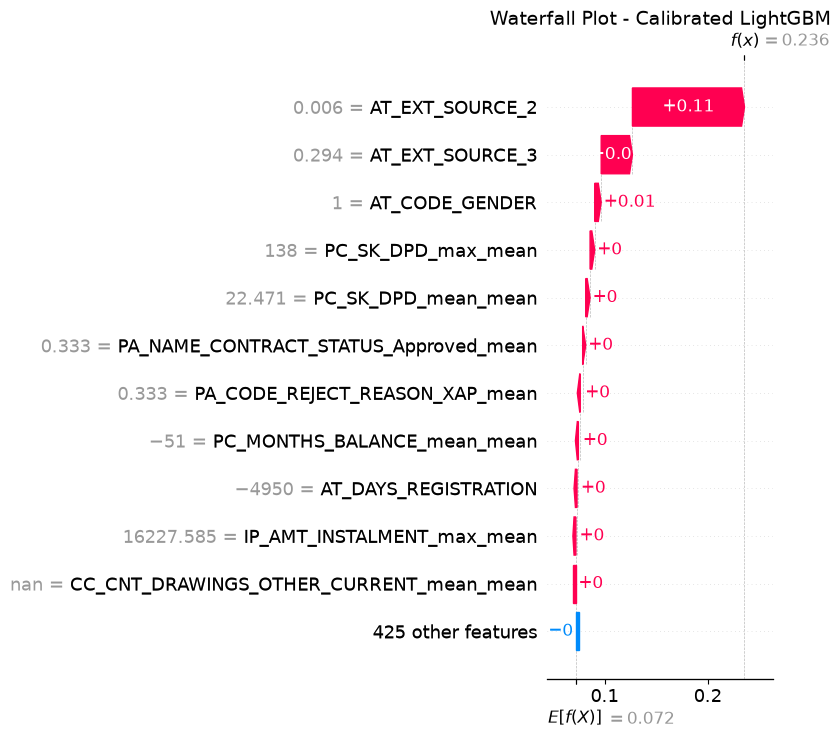

In [28]:
import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
np.random.seed(42)
# --- Giả sử đã có ---
background_summary = shap.utils.sample(background, 100, random_state=42)

def predict_proba_positive(X):
    if isinstance(X, np.ndarray):
        X = pd.DataFrame(X, columns=background_summary.columns)
    return calibrated_lgb_with_weight_tuned_pipeline.predict_proba(X)[:, 1]

explainer = shap.KernelExplainer(predict_proba_positive, background_summary, link="identity")

# Chọn 1 quan sát
X_instance = X_test[-1:]          # quan trọng: phải là DataFrame

# Tính SHAP
shap_values = explainer.shap_values(X_instance, nsamples=500)

# Tạo Explanation
exp = shap.Explanation(
    values = shap_values[0],
    base_values = float(explainer.expected_value),
    data = X_instance.values[0],
    feature_names = X_instance.columns.tolist()
)

# Vẽ
plt.figure(figsize=(10, 8))
shap.plots.waterfall(exp, max_display=12, show=False)
plt.title("Waterfall Plot - Calibrated LightGBM", fontsize=14)
plt.tight_layout()
plt.show()

## Force Plot

In [74]:
shap.initjs()

shap.force_plot(
    base_value,
    shap_class_1,
    X_transformed.iloc[0],
    feature_names=X_transformed.columns.tolist()
)

## Bar Plot

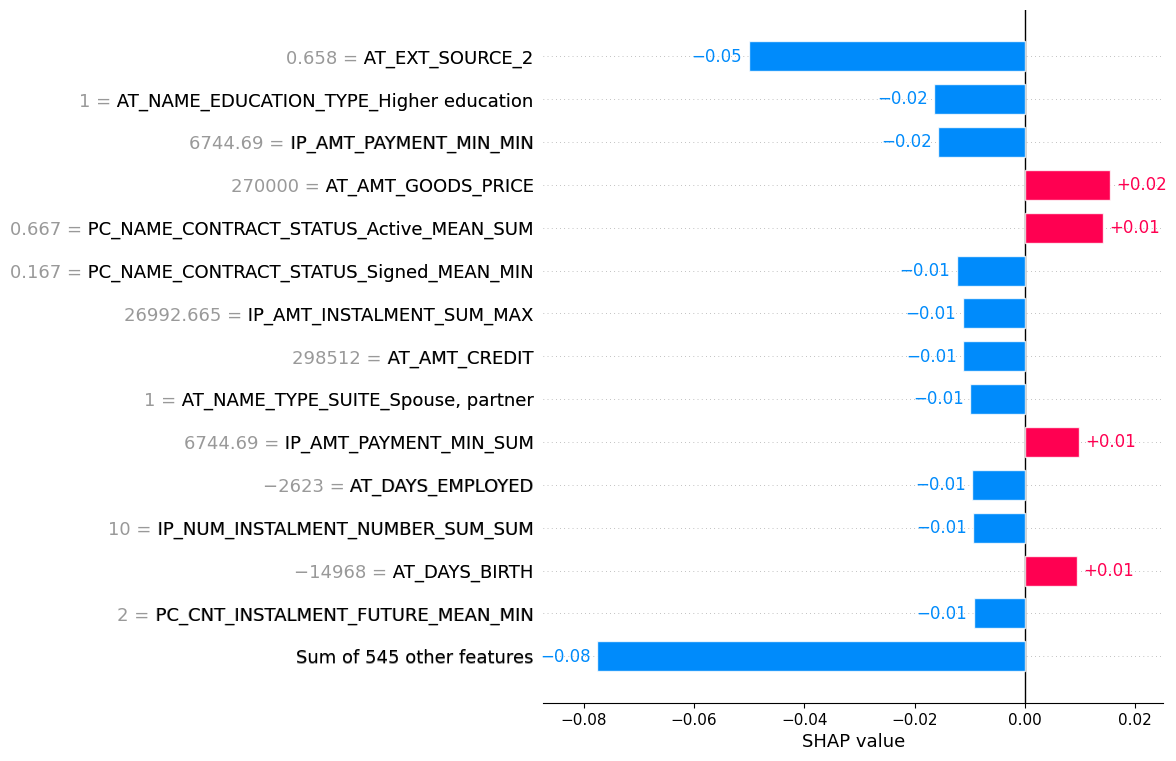

In [75]:
shap.plots.bar(explanation, max_display=15)